In [ ]:
# === 1. Bibliotecas ===

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import pandas as pd
import numpy as np
import tensorflow as tf
import random
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error

seed_value = 42
os.environ['PYTHONHASHSEED'] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.random.set_seed(seed_value)

In [ ]:
# === 2. Carregamento e tratamento dos dados ===
df = pd.read_excel(
    '/content/content/Vazões_Diárias_1931_2016_RESUMIDA_SALTO_CAXIAS.xlsx',
    engine='openpyxl',
    header=0,
    names=['Data', 'Vazao']
)

df['Data'] = pd.to_datetime(df['Data'], dayfirst=True, errors='coerce')
df = df.dropna(subset=['Data', 'Vazao'])
df = df[pd.to_numeric(df['Vazao'], errors='coerce').notnull()]
df['Vazao'] = df['Vazao'].astype(float)
df = df.sort_values('Data')
df['Ano'] = df['Data'].dt.year

train_data = df[df['Ano'] <= 2010].reset_index(drop=True)
test_data = df[df['Ano'] >= 2011].reset_index(drop=True)
train_values = train_data['Vazao'].values
test_values = test_data['Vazao'].values

In [ ]:
# === 3. Criar janelas ===
window_in = 15  #30
window_out = 7
X, y = [], []

for i in range(len(train_values) - window_in - window_out + 1):
    X.append(train_values[i : i + window_in])
    y.append(train_values[i + window_in : i + window_in + window_out])
X = np.array(X)
y = np.array(y)

In [ ]:
# === 4. Normalização ===
# Calcula a média e o desvio padrão com base nos dados de entrada de treinamento (X)
mean = X.mean()
std = X.std()
X = (X - mean) / std
y = (y - mean) / std

In [ ]:
# === 5. Definir o modelo MLP ===
model = Sequential([
    Input(shape=(window_in,)),  # Entrada com 15 neurônios
    Dense(64, activation='relu', kernel_initializer=tf.keras.initializers.RandomUniform(minval=-1.0, maxval=1.0)),
    Dense(32, activation='relu', kernel_initializer=tf.keras.initializers.RandomUniform(minval=-1.0, maxval=1.0)),
    Dense(16, activation='relu', kernel_initializer=tf.keras.initializers.RandomUniform(minval=-1.0, maxval=1.0)),
    Dense(window_out, activation='linear', kernel_initializer=tf.keras.initializers.RandomUniform(minval=-1.0, maxval=1.0))
])
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='mse',
              metrics=['mae'])

model.summary()






Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,751 (14.65 KB)

 Trainable params: 3,751 (14.65 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# === ✅ 6. EarlyStopping ===
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [ ]:

# === 7. Treinamento e validação cruzada com EarlyStopping ===
history = model.fit(
    X, y,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=2
)

Epoch 1/200
559/559 - 3s - 5ms/step - loss: 14.3511 - mae: 1.7056 - val_loss: 1.1915 - val_mae: 0.7455
Epoch 2/200
559/559 - 1s - 2ms/step - loss: 1.1281 - mae: 0.6935 - val_loss: 0.9692 - val_mae: 0.7013
Epoch 3/200
559/559 - 1s - 2ms/step - loss: 1.0371 - mae: 0.6673 - val_loss: 0.9295 - val_mae: 0.6946
Epoch 4/200
559/559 - 2s - 3ms/step - loss: 1.0180 - mae: 0.6602 - val_loss: 0.9170 - val_mae: 0.6926
Epoch 5/200
559/559 - 2s - 4ms/step - loss: 0.8002 - mae: 0.5911 - val_loss: 0.4613 - val_mae: 0.4899
Epoch 6/200
559/559 - 1s - 2ms/step - loss: 0.4786 - mae: 0.4407 - val_loss: 0.3589 - val_mae: 0.3982
Epoch 7/200
559/559 - 1s - 2ms/step - loss: 0.4046 - mae: 0.3746 - val_loss: 0.3218 - val_mae: 0.3472
Epoch 8/200
559/559 - 1s - 2ms/step - loss: 0.3746 - mae: 0.3401 - val_loss: 0.3027 - val_mae: 0.3189
Epoch 9/200
559/559 - 1s - 2ms/step - loss: 0.3583 - mae: 0.3204 - val_loss: 0.2910 - val_mae: 0.3003
Epoch 10/200
559/559 - 1s - 2ms/step - loss: 0.3482 - mae: 0.3081 - val_loss: 0.2

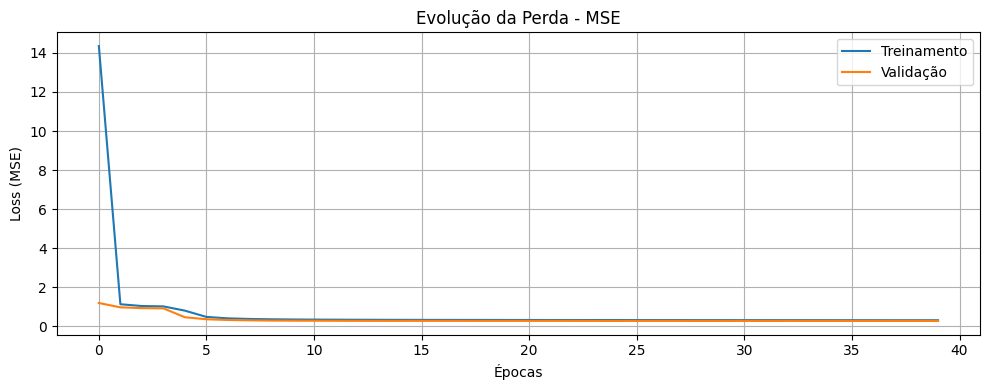

In [ ]:
# === 7.1 Gráfico da perda (loss) ===
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Treinamento')
plt.plot(history.history['val_loss'], label='Validação')
plt.title('Evolução da Perda - MSE')
plt.xlabel('Épocas')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# 7. Fazer previsão para o período de 2011 até 2016
# Cria janelas no mesmo formato para o teste
# Para prever o período de teste, combinamos os últimos dados de treino com os dados de teste.
# Isso garante que a primeira janela de previsão tenha dados históricos suficientes.
# ---

combined_train_test_for_prediction = np.concatenate([train_values[-window_in:], test_values])
n_test_days = len(test_values)
predictions = []

# Loop para fazer previsões de 'window_out' em 'window_out' dias
# Usamos um array 'current_window' que será atualizado com os valores reais ou previstos.
current_window = combined_train_test_for_prediction[0:window_in]

for i in range(0, n_test_days, window_out):
    # Normaliza a janela de entrada
    input_norm = (current_window - mean) / std

    # Faz a previsão
    pred_norm = model.predict(input_norm.reshape(1, -1), verbose=0)

    # Desnormaliza a previsão
    pred_denormalized = pred_norm.flatten() * std + mean

    # Adiciona as previsões à lista
    predictions.extend(pred_denormalized)

    # Atualiza a janela de entrada para a próxima iteração
    # Se ainda houver dados reais disponíveis para a próxima janela, use-os.
    # Caso contrário, as previsões futuras dependerão das previsões anteriores (previsão de múltiplos passos).
    next_actual_segment_start_index = window_in + i + window_out

    if (next_actual_segment_start_index + window_out) <= len(combined_train_test_for_prediction):
        # Se houver dados reais suficientes para a próxima janela inteira, use-os.
        current_window = combined_train_test_for_prediction[next_actual_segment_start_index - window_in : next_actual_segment_start_index]
    else:
        # Se não houver dados reais suficientes, use as previsões para formar a próxima janela.
        # Isso simula um cenário de previsão para o futuro.
        # Pegamos os últimos `window_in - window_out` valores reais/previstos
        # e concatenamos com as `window_out` novas previsões.
        current_window = np.concatenate([current_window[window_out:], pred_denormalized])

# Garante que o tamanho final da previsão não ultrapasse o número de dias de teste
predictions = predictions[:n_test_days]

In [ ]:
# 9. Calcular erro médio absoluto
# ---
# Converter para arrays
true_values = np.array(test_values[:len(predictions)])
pred_values = np.array(predictions)

# Remover quaisquer pares com NaN (embora o pré-processamento já devesse ter lidado com isso)
mask = ~np.isnan(true_values) & ~np.isnan(pred_values)
true_values_clean = true_values[mask]
pred_values_clean = pred_values[mask]

# Calcular MAE
mae = mean_absolute_error(true_values_clean, pred_values_clean)
print(f'Erro Médio Absoluto (MAE): {mae:.2f}')

Erro Médio Absoluto (MAE): 446.18


In [ ]:
# Prever apenas os últimos 7 dias (usando os 15 anteriores)
input_window = test_values[-(window_in + window_out):-window_out]  # últimos 15 dias antes dos 7 finais
input_norm = (input_window - mean) / std

# Fazer previsão
pred_norm = model.predict(input_norm.reshape(1, -1), verbose=0)
pred = pred_norm.flatten() * std + mean

# Dados reais dos últimos 7 dias
true_values_last_7 = test_values[-window_out:]

# Criar datas para visualização
last_7_dates = test_data['Data'].iloc[-window_out:]


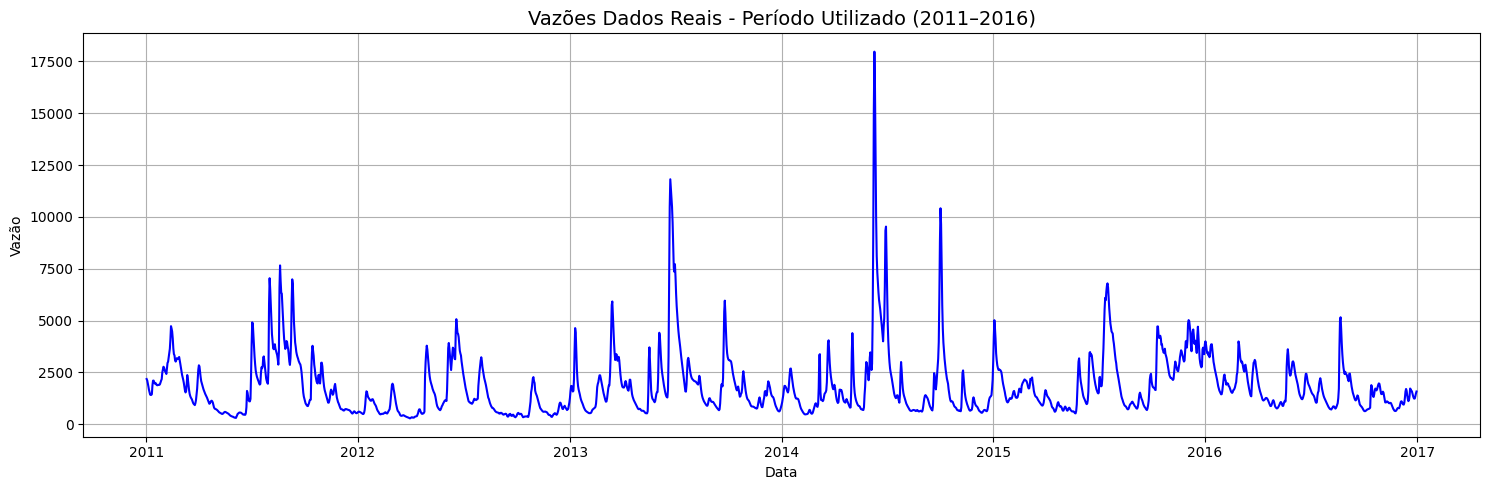

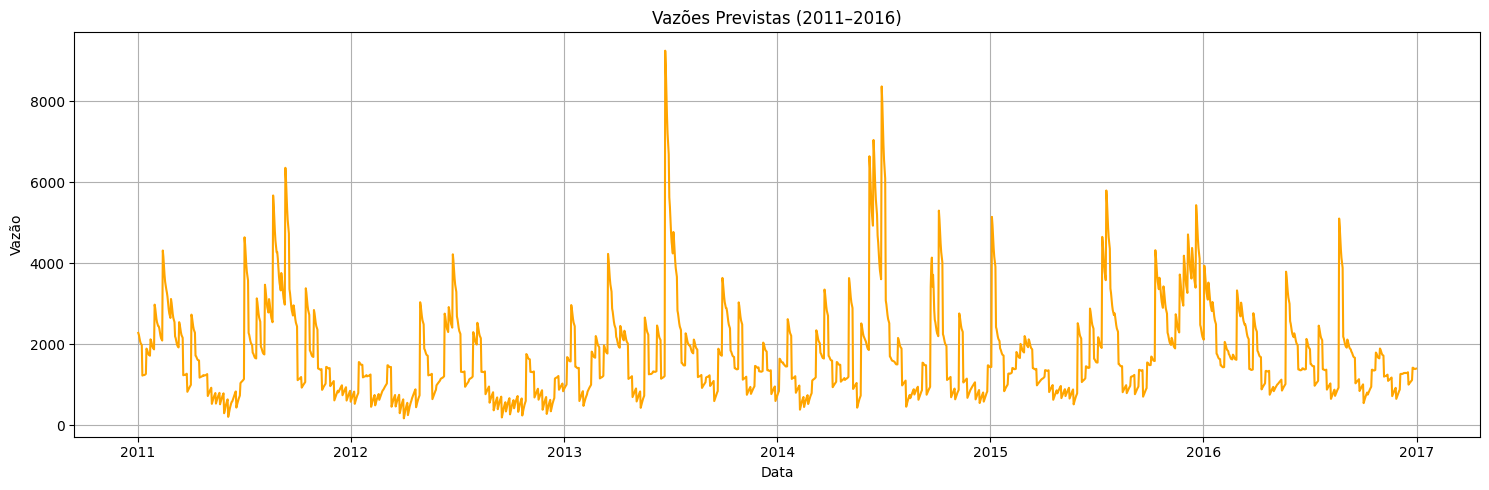

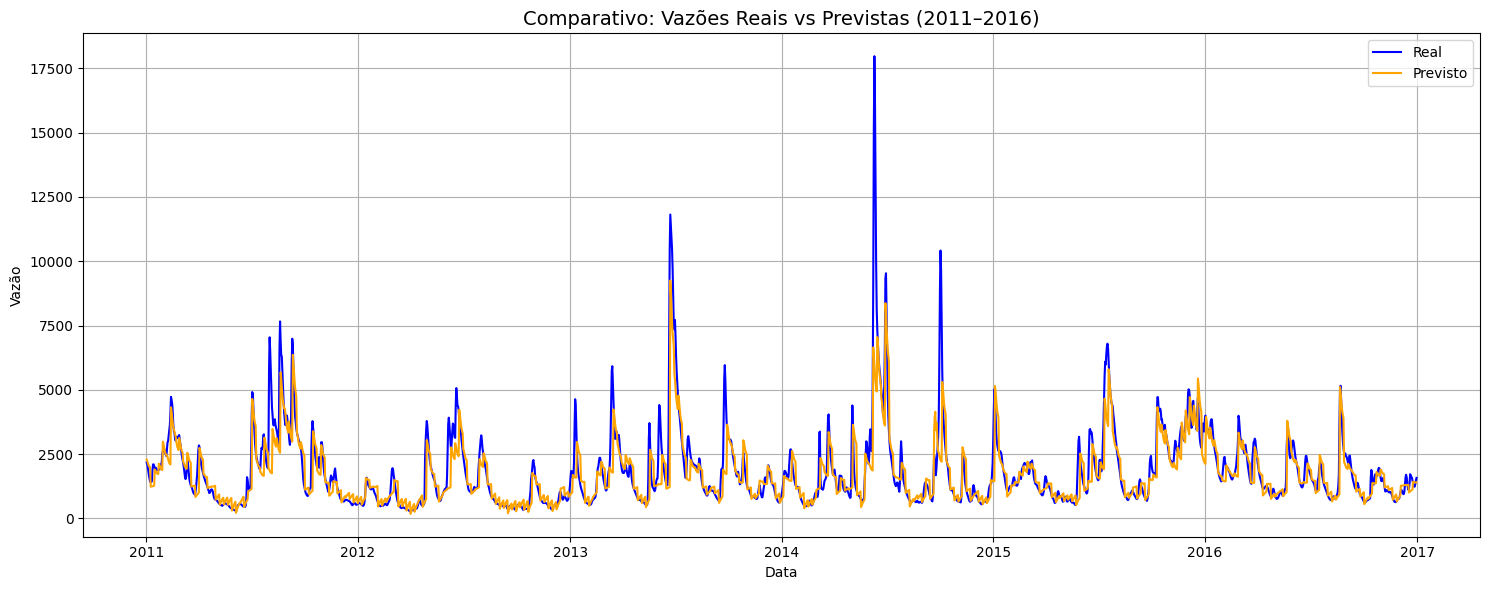

In [ ]:
## 10. Plotar Resultados
# ---

# 10.1 Gráfico apenas dos valores reais
plt.figure(figsize=(15, 5), dpi=100)
plt.plot(test_data['Data'], test_values, color='blue')
plt.title('Vazões Dados Reais - Período Utilizado (2011–2016)', fontsize=14)
plt.xlabel('Data')
plt.ylabel('Vazão')
plt.grid(True)
plt.tight_layout()
plt.show()

# 10.2 Gráfico apenas dos valores previstos
plt.figure(figsize=(15, 5))
plt.plot(test_data['Data'][:len(predictions)], predictions, color='orange')
plt.title('Vazões Previstas (2011–2016)')
plt.xlabel('Data')
plt.ylabel('Vazão')
plt.grid()
plt.tight_layout()
plt.show()

# 10.3 Plotar resultado comparado
plt.figure(figsize=(15, 6), dpi=100)
plt.plot(test_data['Data'], test_values, label='Real', color='blue')
plt.plot(test_data['Data'][:len(predictions)], predictions, label='Previsto', color='orange')
plt.title('Comparativo: Vazões Reais vs Previstas (2011–2016)', fontsize=14)
plt.xlabel('Data')
plt.ylabel('Vazão')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



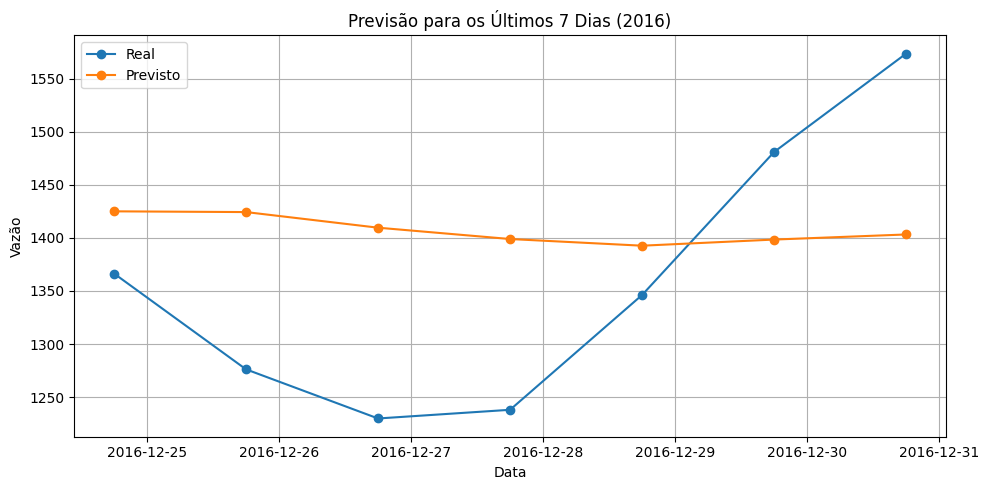

In [ ]:
## 11. Previsão para os Últimos 7 Dias (Zoom In)
# Esta seção foca especificamente na previsão dos últimos `window_out` dias do conjunto de teste,
# usando os `window_in` dias imediatamente anteriores a eles como entrada.
# ---
# Os últimos `window_in` dias ANTES dos últimos `window_out` dias do test_values
input_window_last_7 = test_values[-(window_in + window_out):-window_out]
input_norm_last_7 = (input_window_last_7 - mean) / std

# Fazer previsão para os últimos 7 dias
pred_norm_last_7 = model.predict(input_norm_last_7.reshape(1, -1), verbose=0)
pred_last_7_denormalized = pred_norm_last_7.flatten() * std + mean

# Dados reais dos últimos 7 dias
true_values_last_7 = test_values[-window_out:]

# Criar datas para visualização
last_7_dates = test_data['Data'].iloc[-window_out:]

# Plotar resultado da previsão dos últimos 7 dias
plt.figure(figsize=(10, 5))
plt.plot(last_7_dates, true_values_last_7, label='Real', marker='o')
plt.plot(last_7_dates, pred_last_7_denormalized, label='Previsto', marker='o')
plt.title(f'Previsão para os Últimos {window_out} Dias (2016)')
plt.xlabel('Data')
plt.ylabel('Vazão')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()